# VM Resource Forecasting

## Project objective

The objective of this project is to forecast two aggregate metrics over the next 24 observations (two hours):

- Active virtual machine count.
- Aggregate CPU utilisation.

The source data contains VM-level CPU readings sampled every five minutes. The VM-level readings are aggregated by timestamp before the chronological training and holdout split.

The modelling process follows a baseline-first approach. Candidate models are compared using rolling-origin validation on the training period. The final 24 observations are kept separate for the final evaluation.


## 1. Load libraries and data

Import the Python libraries used for data manipulation, numerical operations, visualisation and exploratory analysis.

The CPU readings and VM metadata are loaded separately. The CPU readings are used to construct the aggregate time series. Metadata is retained for dataset understanding and possible supporting analysis.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



## 2. Inspect the dataset

Review the dimensions, column names and sample records of both files.

This step confirms that the expected fields are present and helps distinguish VM-level measurements from VM-level metadata.


In [6]:

cpu = pd.read_csv("/home/mayankk/forecasting-challenge/dataset/vm_cpu_readings.csv")
metadata = pd.read_csv("/home/mayankk/forecasting-challenge/dataset/vm_metadata.csv")

print("CPU shape:", cpu.shape)
print("Metadata shape:", metadata.shape)

CPU shape: (1340000, 5)
Metadata shape: (10000, 11)


## 3. Data quality checks

Check for missing values and duplicate records.

For CPU readings, the combination of VM identifier and timestamp should uniquely identify an observation. For metadata, each VM identifier should appear once.

These checks help identify data-quality issues before aggregation and modelling.


In [7]:
print("CPU columns:")
print(cpu.columns.tolist())

print("\nMetadata columns:")
print(metadata.columns.tolist())

display(cpu.head())
display(metadata.head())

CPU columns:
['timestamp', 'vm_id', 'min_cpu', 'max_cpu', 'avg_cpu']

Metadata columns:
['vm_id', 'subscription_id', 'deployment_id', 'timestamp_vm_created', 'timestamp_vm_deleted', 'max_cpu', 'avg_cpu', 'p95_max_cpu', 'vm_category', 'virtual_core_bucket', 'memory_gb_bucket']


,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


,vm_id,subscription_id,deployment_id,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu,vm_category,virtual_core_bucket,memory_gb_bucket
0,FpzMJdMf8qtHmtOG8tkLZzGwGyipMwLXrWaOB9t83llPSU...,zidmVREtoQ8LZn7hurMi6cpBzixgqQWaYI1dDjz+KHaLRE...,gFCpVCrXZfTE26Jz92rA1lBddtl3tjwT0DKwPsxVITF73e...,0,2591400,76.317105,4.770387,8.491848,Delay-insensitive,2,2
1,BH2lz1WPrkc3OhPzE5+mecvo3sum6s14EvcZLFN/lqH9w4...,JOJ5q+T2F5zCr4CzSwPxfZgGVFfdKdzjjyZYGRu6hnomvn...,+qsl6upF4G6CBnFVK97vb0yE1lC551CWp9U1lcfnZKmz1Q...,0,406200,96.755318,0.699635,23.814289,Unknown,8,64
2,vstJO/1LuWKseZPzWayfdckE5FnkWLmqaWziPASYuJdPoh...,0kctkGk351EZ4Sj1AIzheqbGJ5hlYjCbuyZHXtr8PT2Ubg...,TJuS+gMfk5LBg0+dHsOwoQdDyYYCu7YS60KJkeVuxOyaEN...,0,2591400,83.110403,5.878783,11.293819,Delay-insensitive,2,4
3,88rAudRS2akNM+S6uHDTXAq6YE+1z27wota+723juDdmcY...,4qyOW7DwhjSolTnKK27cY1ELmu2hqpBNkgiHsfTOex2UUb...,yfPM2qpoqC9aXMgM7S0mCLxCY8NEd4C6uiLpfY443SV5Yj...,0,70200,98.738842,81.578650,98.439173,Unknown,4,8
4,C+lO8PpCWNqnq5dIhv4Mu74NxH8HHYC0/EKOatNq6YHe04...,1PDByEqjMhhy8jWbS/5ttawogqgyACcOAWYVk3rbt3ouVU...,hrP166UPejKeASJ3ibhQ68YrE7iDxsmlXNZ2B8BBy0BMKn...,0,2591400,90.790129,2.382323,6.902215,Delay-insensitive,2,4


## 4. Check VM and timestamp coverage

Count the unique VMs and timestamps, and inspect the number of observations available for each VM.

The dataset is expected to contain a consistent number of observations per VM. This check also helps confirm whether the time series has a regular observation structure.


In [8]:
print("CPU missing values:")
print(cpu.isnull().sum())

print("\nMetadata missing values:")
print(metadata.isnull().sum())

print("\nDuplicate CPU records:")
print(cpu.duplicated(["vm_id", "timestamp"]).sum())

print("\nDuplicate metadata VM IDs:")
print(metadata["vm_id"].duplicated().sum())

CPU missing values:
timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64

Metadata missing values:
vm_id                   0
subscription_id         0
deployment_id           0
timestamp_vm_created    0
timestamp_vm_deleted    0
max_cpu                 0
avg_cpu                 0
p95_max_cpu             0
vm_category             0
virtual_core_bucket     0
memory_gb_bucket        0
dtype: int64

Duplicate CPU records:
0

Duplicate metadata VM IDs:
0


## 5. Aggregate VM-level readings

The forecasting targets are constructed at timestamp level:

- Active VM count is the number of distinct VMs with a valid reading at each timestamp.
- Aggregate CPU utilisation is the mean of the VM-level average CPU readings at each timestamp.

The resulting table contains one row per timestamp and is sorted chronologically.


In [9]:
print("Unique VMs:", cpu["vm_id"].nunique())
print("Unique timestamps:", cpu["timestamp"].nunique())

print("\nObservations per VM:")
print(cpu.groupby("vm_id").size().value_counts())

Unique VMs: 10000
Unique timestamps: 134

Observations per VM:
134    10000
Name: count, dtype: int64


## 6. Inspect aggregate time-series statistics

Review descriptive statistics for both targets and inspect the time difference between consecutive observations.

A regular interval is important for interpreting forecast horizons. At a five-minute cadence, 24 future observations represent two hours.


In [10]:
ts = (
    cpu.groupby("timestamp")
    .agg(
        active_vm_count=("vm_id", "nunique"),
        aggregate_cpu_utilization=("avg_cpu", "mean")
    )
    .reset_index()
    .sort_values("timestamp")
)

display(ts.head())
display(ts.tail())

print("Time series shape:", ts.shape)

,timestamp,active_vm_count,aggregate_cpu_utilization
0,0,10000,9.396898
1,300,10000,9.353775
2,600,10000,9.454383
3,900,10000,9.224419
4,1200,10000,9.143503


,timestamp,active_vm_count,aggregate_cpu_utilization
129,38700,10000,9.430236
130,39000,10000,9.307138
131,39300,10000,9.499973
132,39600,10000,9.423042
133,39900,10000,9.428117


Time series shape: (134, 3)


## 7. Visualise the aggregate targets

Plot active VM count and aggregate CPU utilisation over time.

The plots provide an initial view of changes, variability and possible trends. They also help determine whether both targets require non-constant forecasting approaches.


In [11]:
print(ts[["active_vm_count", "aggregate_cpu_utilization"]].describe())

print("\nTimestamp intervals:")
print(ts["timestamp"].diff().value_counts())

print("\nUnique active VM counts:")
print(ts["active_vm_count"].value_counts())

       active_vm_count  aggregate_cpu_utilization
count            134.0                 134.000000
mean           10000.0                   9.388101
std                0.0                   0.194987
min            10000.0                   8.983613
25%            10000.0                   9.250956
50%            10000.0                   9.367252
75%            10000.0                   9.485657
max            10000.0                   9.912175

Timestamp intervals:
timestamp
300.0    133
Name: count, dtype: int64

Unique active VM counts:
active_vm_count
10000    134
Name: count, dtype: int64


## 8. Chronological training and holdout split

The first 110 aggregate observations are assigned to the training set. The final 24 observations are reserved as the holdout set.

The holdout period represents the 24-step forecast horizon. Its target values must not be used for model selection, feature selection or parameter tuning.


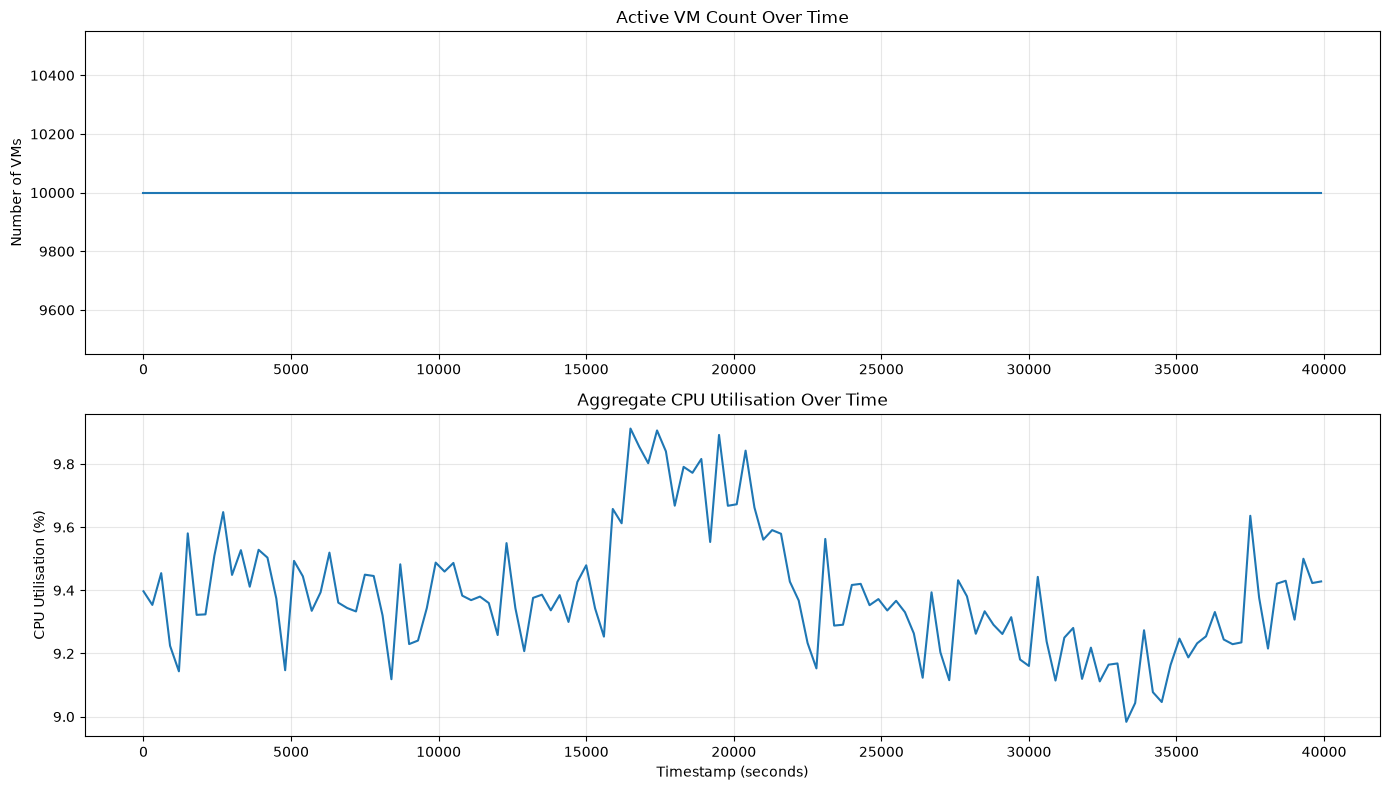

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(
    ts["timestamp"],
    ts["active_vm_count"]
)
axes[0].set_title("Active VM Count Over Time")
axes[0].set_ylabel("Number of VMs")
axes[0].grid(alpha=0.3)

axes[1].plot(
    ts["timestamp"],
    ts["aggregate_cpu_utilization"]
)
axes[1].set_title("Aggregate CPU Utilisation Over Time")
axes[1].set_xlabel("Timestamp (seconds)")
axes[1].set_ylabel("CPU Utilisation (%)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Explore CPU utilisation in the training period

Visualise aggregate CPU utilisation using only the training observations.

This plot is used to inspect the historical level, local fluctuations and any visible changes in behaviour without examining the holdout target values.


In [13]:
train = ts.iloc[:110].copy()
holdout = ts.iloc[110:].copy()

print("Training shape:", train.shape)
print("Holdout shape:", holdout.shape)

print("Training period:",
      train["timestamp"].min(),
      "to",
      train["timestamp"].max())

print("Holdout period:",
      holdout["timestamp"].min(),
      "to",
      holdout["timestamp"].max())

Training shape: (110, 3)
Holdout shape: (24, 3)
Training period: 0 to 32700
Holdout period: 33000 to 39900


## 10. Rolling mean and rolling standard deviation

Calculate rolling statistics using a 12-observation window, equivalent to one hour.

The rolling mean provides a view of local level changes. The rolling standard deviation provides a view of local variability. These statistics help assess whether the series has a stable level and variance.


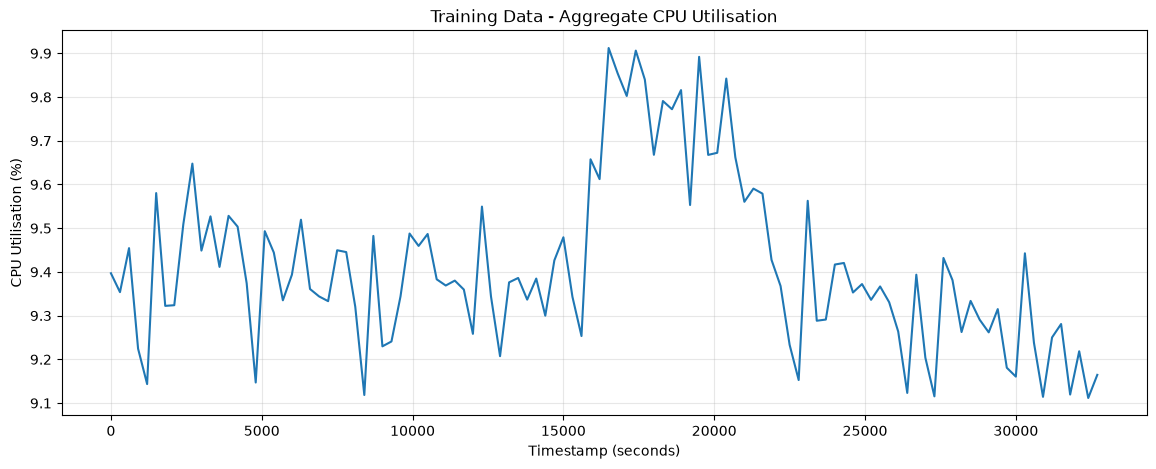

In [14]:
plt.figure(figsize=(14, 5))

plt.plot(
    train["timestamp"],
    train["aggregate_cpu_utilization"]
)

plt.title("Training Data - Aggregate CPU Utilisation")
plt.xlabel("Timestamp (seconds)")
plt.ylabel("CPU Utilisation (%)")
plt.grid(alpha=0.3)

plt.show()

## 11. Augmented Dickey-Fuller stationarity test

Apply the Augmented Dickey-Fuller (ADF) test to the original training CPU series and its first difference.

The ADF test has a unit-root null hypothesis. A small p-value provides evidence against the unit-root null. The results are considered alongside the KPSS test rather than interpreted in isolation.


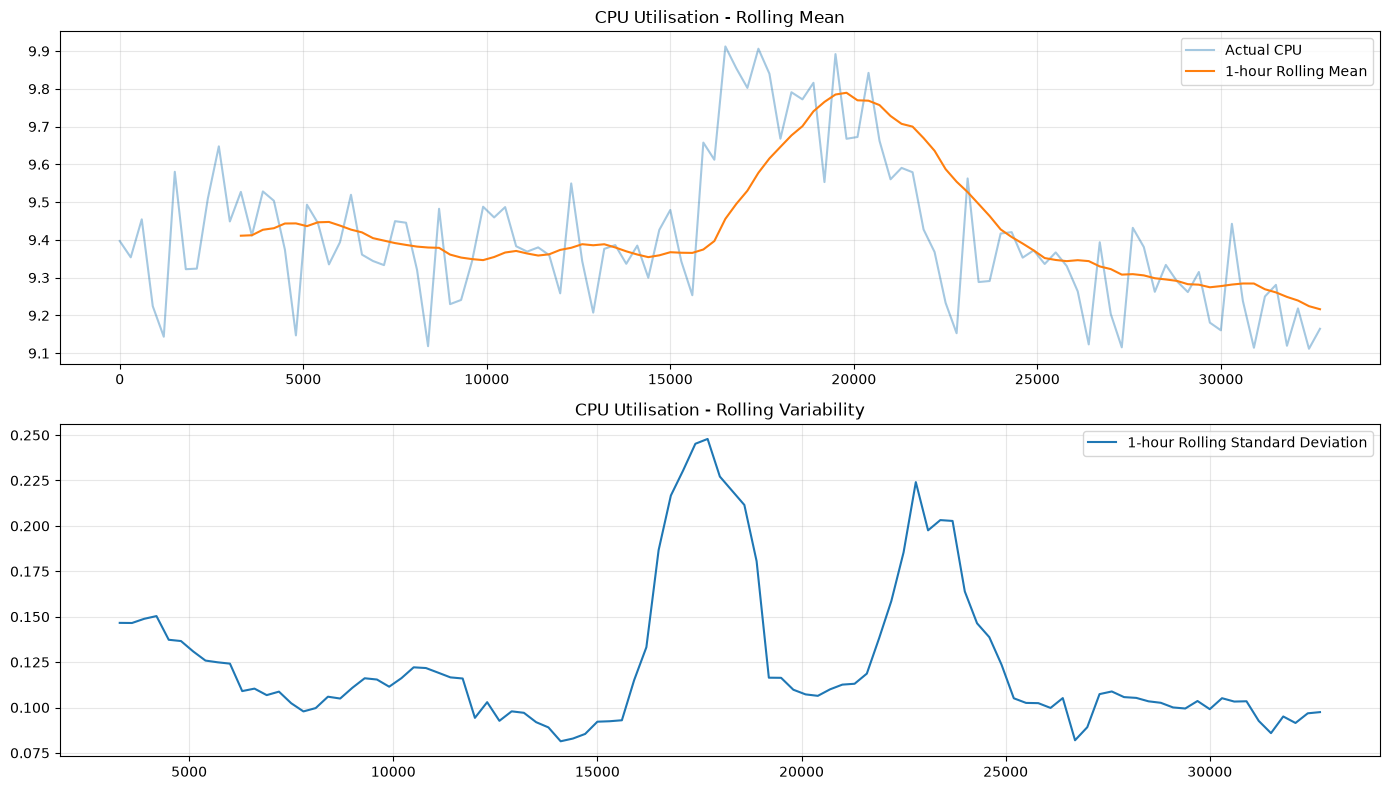

In [15]:
train["rolling_mean"] = (
    train["aggregate_cpu_utilization"]
    .rolling(window=12)
    .mean()
)

train["rolling_std"] = (
    train["aggregate_cpu_utilization"]
    .rolling(window=12)
    .std()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(
    train["timestamp"],
    train["aggregate_cpu_utilization"],
    alpha=0.4,
    label="Actual CPU"
)

axes[0].plot(
    train["timestamp"],
    train["rolling_mean"],
    label="1-hour Rolling Mean"
)

axes[0].set_title("CPU Utilisation - Rolling Mean")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    train["timestamp"],
    train["rolling_std"],
    label="1-hour Rolling Standard Deviation"
)

axes[1].set_title("CPU Utilisation - Rolling Variability")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 12. KPSS stationarity test

Apply the KPSS test to the original training CPU series and its first difference.

The KPSS test uses stationarity as its null hypothesis, which is the opposite framing to the ADF test. Considering both tests provides a more balanced assessment. A reported p-value at the test's lookup boundary should be interpreted as a bound rather than an exact probability.


In [21]:
from statsmodels.tsa.stattools import adfuller

cpu_series = train["aggregate_cpu_utilization"]

adf_original = adfuller(
    cpu_series,
    autolag="AIC",
    result_object=True
)

adf_diff = adfuller(
    cpu_series.diff().dropna(),
    autolag="AIC",
    result_object=True
)

print("Original Series")
print("ADF Statistic:", adf_original.statistic)
print("p-value:", adf_original.pvalue)
print("Critical Values:", adf_original.critical_values)

print("\nFirst-Differenced Series")
print("ADF Statistic:", adf_diff.statistic)
print("p-value:", adf_diff.pvalue)
print("Critical Values:", adf_diff.critical_values)

Original Series
ADF Statistic: -1.7348231782505086
p-value: 0.4132656887034393
Critical Values: {'1%': np.float64(-3.4996365338407074), '5%': np.float64(-2.8918307730370025), '10%': np.float64(-2.5829283377617176)}

First-Differenced Series
ADF Statistic: -2.680797784747952
p-value: 0.07742044012297196
Critical Values: {'1%': np.float64(-3.4996365338407074), '5%': np.float64(-2.8918307730370025), '10%': np.float64(-2.5829283377617176)}


## 13. ACF and PACF analysis

Plot the autocorrelation function (ACF) and partial autocorrelation function (PACF) for the original and first-differenced training series.

These plots help inspect short-term dependence and possible repeating patterns. Seasonal structure should not be assumed from an isolated autocorrelation spike; it should be supported by a consistent pattern and sufficient observed cycles.


In [22]:
from statsmodels.tsa.stattools import kpss

# Original series
kpss_original = kpss(
    cpu_series,
    regression="c",
    nlags="auto"
)

# First-differenced series
kpss_diff = kpss(
    cpu_series.diff().dropna(),
    regression="c",
    nlags="auto"
)

print("Original Series")
print("KPSS Statistic:", kpss_original[0])
print("p-value:", kpss_original[1])

print("\nFirst-Differenced Series")
print("KPSS Statistic:", kpss_diff[0])
print("p-value:", kpss_diff[1])

Original Series
KPSS Statistic: 0.3074795760913044
p-value: 0.1

First-Differenced Series
KPSS Statistic: 0.1406223221342708
p-value: 0.1


/tmp/ipykernel_8126/225349988.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_original = kpss(
/tmp/ipykernel_8126/225349988.py:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_original = kpss(
/tmp/ipykernel_8126/225349988.py:11: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_diff = kpss(
/tmp/ipykernel_8126/225349988.py:11: FutureWarning: kpss currently returns a plain tuple whose 

## 14. Inspect selected autocorrelation lags

Print autocorrelation values at selected lags.

At a five-minute sampling interval, lag 12 corresponds to one hour and lag 24 corresponds to two hours. These values help assess whether there is evidence of repeating hourly or two-hourly behaviour.


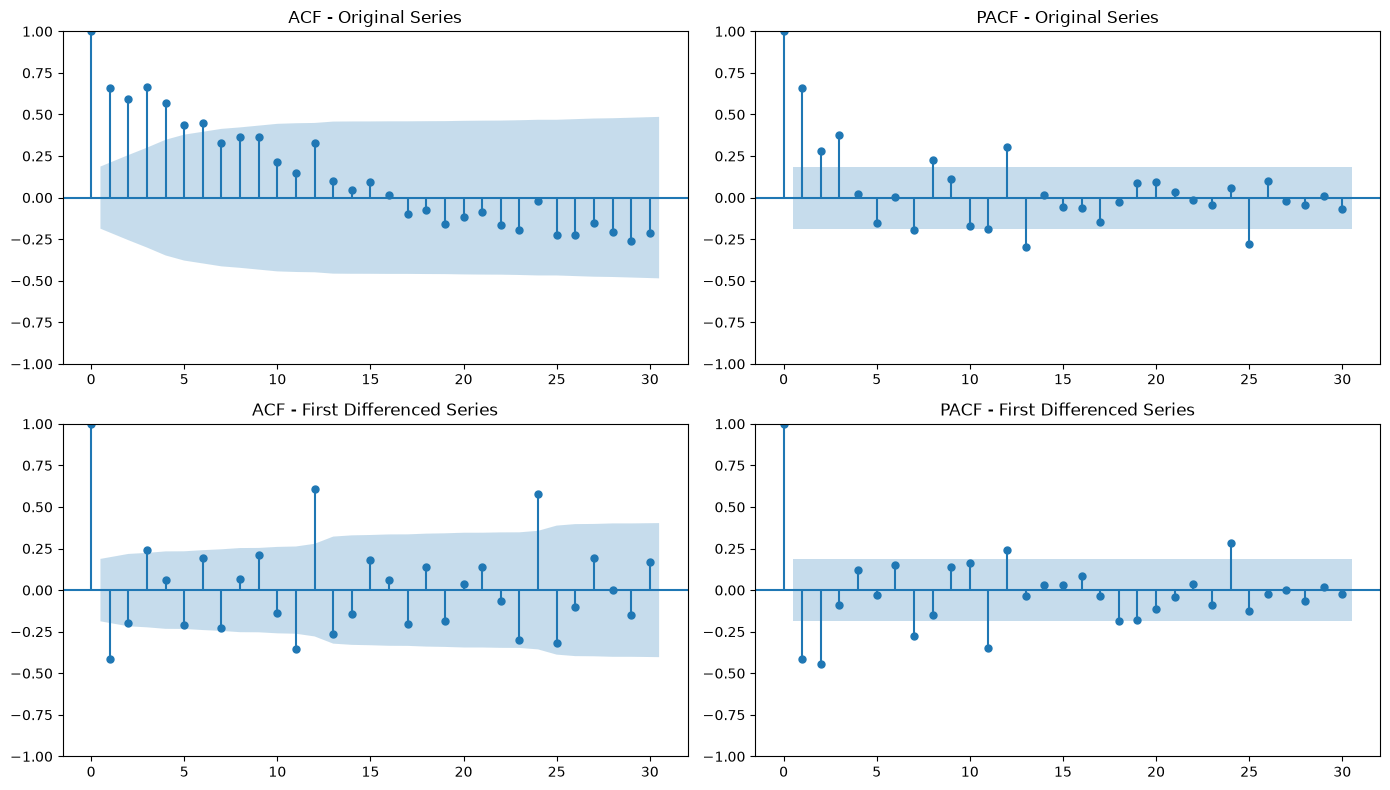

In [23]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_acf(cpu_series, lags=30, ax=axes[0, 0])
axes[0, 0].set_title("ACF - Original Series")

plot_pacf(cpu_series, lags=30, ax=axes[0, 1], method="ywm")
axes[0, 1].set_title("PACF - Original Series")

diff_series = cpu_series.diff().dropna()

plot_acf(diff_series, lags=30, ax=axes[1, 0])
axes[1, 0].set_title("ACF - First Differenced Series")

plot_pacf(diff_series, lags=30, ax=axes[1, 1], method="ywm")
axes[1, 1].set_title("PACF - First Differenced Series")

plt.tight_layout()
plt.show()

## 15. Check selected lag correlations directly

Calculate the training series' autocorrelation at lags 12 and 24 as an additional check of possible hourly and two-hourly dependence.

The dataset contains a limited number of hourly cycles, so any apparent seasonal pattern should be treated cautiously.


In [24]:
from statsmodels.tsa.stattools import acf

acf_values = acf(
    cpu_series,
    nlags=36,
    fft=False
)

print("Autocorrelation at selected lags:")

for lag in [1, 2, 3, 6, 12, 18, 24, 30, 36]:
    print(f"Lag {lag}: {acf_values[lag]:.4f}")

Autocorrelation at selected lags:
Lag 1: 0.6621
Lag 2: 0.5946
Lag 3: 0.6640
Lag 6: 0.4498
Lag 12: 0.3274
Lag 18: -0.0722
Lag 24: -0.0199
Lag 30: -0.2124
Lag 36: -0.1868


## 16. Simple CPU baselines

Create two constant-horizon forecasting baselines:

- Naive forecast: repeat the last observed training value.
- Historical-mean forecast: repeat the mean of the available training observations.

These simple forecasts establish reference performance. More complex models should only be retained if they demonstrate an improvement under the same validation design.


In [25]:
print(
    "Lag-12 correlation:",
    cpu_series.autocorr(lag=12)
)

print(
    "Lag-24 correlation:",
    cpu_series.autocorr(lag=24)
)

Lag-12 correlation: 0.36661232457585463
Lag-24 correlation: -0.026381275989691828


## 17. Rolling-origin validation for baseline models

Compare the naive and historical-mean forecasts using expanding training windows and a 24-observation validation horizon.

The forecast origins are 62, 74 and 86 observations. Each validation window remains within the first 110 observations, so the final holdout is not used for model selection.

The validation windows overlap, meaning their errors are not independent. This limitation should be acknowledged when interpreting the average metrics.


In [26]:
import numpy as np

y = train["aggregate_cpu_utilization"].to_numpy()

# Baseline 1: Last observed value
naive_forecast = np.repeat(y[-1], 24)

# Baseline 2: Training mean
mean_forecast = np.repeat(y.mean(), 24)

print("Last training value:", y[-1])
print("Training mean:", y.mean())

print("Naive forecast:", naive_forecast[:5])
print("Mean forecast:", mean_forecast[:5])

Last training value: 9.164556174985146
Training mean: 9.414089019539007
Naive forecast: [9.16455617 9.16455617 9.16455617 9.16455617 9.16455617]
Mean forecast: [9.41408902 9.41408902 9.41408902 9.41408902 9.41408902]


## 18. Simple Exponential Smoothing

Evaluating Simple Exponential Smoothing (SES) using the same rolling-origin folds and forecast horizon.

SES assigns exponentially decreasing weights to older observations. The smoothing parameter is estimated separately within each fold. Its performance is compared with the simple baselines using MAE, RMSE and sMAPE.


In [ ]:
import numpy as np
import pandas as pd

y = train["aggregate_cpu_utilization"].to_numpy()

origins = [62, 74, 86]
horizon = 24

results = []

for origin in origins:

    history = y[:origin]
    actual = y[origin:origin + horizon]

    # Naive forecast
    naive = np.repeat(history[-1], horizon)

    # Historical mean forecast
    mean = np.repeat(history.mean(), horizon)

    for model_name, prediction in [
        ("Naive", naive),
        ("Mean", mean)
    ]:

        mae = np.mean(np.abs(actual - prediction))
        rmse = np.sqrt(np.mean((actual - prediction) ** 2))

        smape = np.mean(
            200 * np.abs(actual - prediction) /
            (np.abs(actual) + np.abs(prediction))
        )

        results.append({
            "origin": origin,
            "model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "sMAPE": smape
        })

validation_results = pd.DataFrame(results)

display(validation_results)

print("\nAverage performance across folds:")
display(
    validation_results.groupby("model")[
        ["MAE", "RMSE", "sMAPE"]
    ].mean().sort_values("MAE")
)

,origin,model,MAE,RMSE,sMAPE
0,62,Naive,0.297486,0.345731,3.101636
1,62,Mean,0.172665,0.209938,1.814245
2,74,Naive,0.124450,0.152192,1.332398
3,74,Mean,0.170675,0.192909,1.821349
4,86,Naive,0.132429,0.154228,1.427010
5,86,Mean,0.210492,0.233123,2.255899



Average performance across folds:


,MAE,RMSE,sMAPE
model,,,
Mean,0.184611,0.211990,1.963831
Naive,0.184788,0.217384,1.953682


## 19. ARIMA model comparison

Evaluating a small set of ARIMA configurations with first differencing:

- ARIMA(1, 1, 0)
- ARIMA(0, 1, 1)
- ARIMA(1, 1, 1)

The models are fitted independently within each rolling-origin fold. Small configurations are used because the training history is short. Model complexity is not treated as evidence of better forecasting performance.


In [28]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

ses_results = []

for origin in origins:

    history = y[:origin]
    actual = y[origin:origin + horizon]

    model = SimpleExpSmoothing(
        history,
        initialization_method="estimated"
    ).fit(optimized=True)

    prediction = model.forecast(horizon)

    mae = np.mean(np.abs(actual - prediction))
    rmse = np.sqrt(np.mean((actual - prediction) ** 2))

    smape = np.mean(
        200 * np.abs(actual - prediction) /
        (np.abs(actual) + np.abs(prediction))
    )

    ses_results.append({
        "fold": origin,
        "MAE": mae,
        "RMSE": rmse,
        "sMAPE": smape,
        "alpha": model.params["smoothing_level"]
    })

ses_df = pd.DataFrame(ses_results)

display(ses_df)

,fold,MAE,RMSE,sMAPE,alpha
0,62,0.286148,0.333484,2.985794,0.407049
1,74,0.224649,0.244852,2.388945,0.399136
2,86,0.128759,0.150086,1.387821,0.427016


## 20. Holt's linear trend method

Evaluating Holt's method using the same validation folds.

Holt's method extends exponential smoothing by including a trend component. This experiment tests whether extrapolating a local trend improves the forecast. The trend component is retained only if validation results support it.


In [29]:
from statsmodels.tsa.arima.model import ARIMA

arima_orders = [
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1)
]

arima_results = []

for origin in origins:

    history = y[:origin]
    actual = y[origin:origin + horizon]

    for order in arima_orders:

        try:
            model = ARIMA(
                history,
                order=order,
                trend="n"
            ).fit()

            prediction = model.forecast(steps=horizon)

            mae = np.mean(np.abs(actual - prediction))
            rmse = np.sqrt(np.mean((actual - prediction) ** 2))

            smape = np.mean(
                200 * np.abs(actual - prediction) /
                (np.abs(actual) + np.abs(prediction))
            )

            arima_results.append({
                "fold": origin,
                "model": f"ARIMA{order}",
                "MAE": mae,
                "RMSE": rmse,
                "sMAPE": smape
            })

        except Exception as e:
            print(f"ARIMA{order}, fold {origin}: {e}")

arima_df = pd.DataFrame(arima_results)

display(arima_df)

display(
    arima_df.groupby("model")[["MAE", "RMSE", "sMAPE"]]
    .mean()
    .sort_values("MAE")
)

,fold,model,MAE,RMSE,sMAPE
0,62,"ARIMA(1, 1, 0)",0.273641,0.318666,2.857802
1,62,"ARIMA(0, 1, 1)",0.286148,0.333483,2.985792
2,62,"ARIMA(1, 1, 1)",0.286339,0.333671,2.987751
3,74,"ARIMA(1, 1, 0)",0.165512,0.187889,1.766858
4,74,"ARIMA(0, 1, 1)",0.222697,0.242919,2.368482
5,74,"ARIMA(1, 1, 1)",0.218433,0.238632,2.323753
6,86,"ARIMA(1, 1, 0)",0.126365,0.147542,1.362240
7,86,"ARIMA(0, 1, 1)",0.128721,0.150043,1.387408
8,86,"ARIMA(1, 1, 1)",0.128255,0.149538,1.382434


,MAE,RMSE,sMAPE
model,,,
"ARIMA(1, 1, 0)",0.188506,0.218032,1.995633
"ARIMA(1, 1, 1)",0.211009,0.240614,2.231313
"ARIMA(0, 1, 1)",0.212522,0.242148,2.247227


## 21. Validate the active VM count baseline

Evaluating a persistence forecast for active VM count using the same rolling-origin folds.

If the count remains constant throughout the training and validation periods, repeating the latest observed count should produce zero validation error. This behaviour is specific to the observed dataset and should not be assumed for all production workloads.


In [30]:
from statsmodels.tsa.holtwinters import Holt

holt_results = []

for origin in origins:

    history = y[:origin]
    actual = y[origin:origin + horizon]

    model = Holt(
        history,
        initialization_method="estimated"
    ).fit(optimized=True)

    prediction = model.forecast(horizon)

    mae = np.mean(np.abs(actual - prediction))
    rmse = np.sqrt(np.mean((actual - prediction) ** 2))

    smape = np.mean(
        200 * np.abs(actual - prediction) /
        (np.abs(actual) + np.abs(prediction))
    )

    holt_results.append({
        "fold": origin,
        "MAE": mae,
        "RMSE": rmse,
        "sMAPE": smape,
        "smoothing_level": model.params["smoothing_level"],
        "smoothing_trend": model.params["smoothing_trend"]
    })

holt_df = pd.DataFrame(holt_results)

display(holt_df)
display(holt_df[["MAE", "RMSE", "sMAPE"]].mean())

,fold,MAE,RMSE,sMAPE,smoothing_level,smoothing_trend
0,62,0.374143,0.436902,3.879422,0.380336,0.000000
1,74,0.258242,0.278455,2.740289,0.394170,0.000000
2,86,0.102991,0.123164,1.111888,0.395081,0.002882


MAE      0.245125
RMSE     0.279507
sMAPE    2.577199
dtype: float64

## 22. Fit the selected models and create the forecast

After comparing candidate models, use the selected approach for each target:

- Active VM count: repeat the latest observed training count.
- Aggregate CPU utilisation: repeat the mean of the 110 training observations.

Generate forecasts for the 24 timestamps in the reserved forecast horizon. The holdout timestamps are used only to identify the forecast timestamps, not to access holdout target values.


In [31]:
count_series = train["active_vm_count"].to_numpy()

count_results = []

for origin in origins:

    history = count_series[:origin]
    actual = count_series[origin:origin + horizon]

    prediction = np.repeat(history[-1], horizon)

    count_results.append({
        "fold": origin,
        "MAE": np.mean(np.abs(actual - prediction)),
        "RMSE": np.sqrt(np.mean((actual - prediction) ** 2))
    })

display(pd.DataFrame(count_results))

,fold,MAE,RMSE
0,62,0.0,0.0
1,74,0.0,0.0
2,86,0.0,0.0


## 23. Check the submission file

Read the saved prediction CSV and verify its required column names and order, row count, chronological ordering, five-minute spacing, missing values and numeric validity.

The expected submission contains 24 rows and exactly three columns: timestamp, active_vm_count and aggregate_cpu_utilization.


In [32]:
import numpy as np
import pandas as pd

# Fit using all 110 training observations
cpu_forecast = train["aggregate_cpu_utilization"].mean()

count_forecast = train["active_vm_count"].iloc[-1]

# Future timestamps: 24 observations after training
future_timestamps = holdout["timestamp"].to_numpy()

predictions = pd.DataFrame({
    "timestamp": future_timestamps,
    "active_vm_count": count_forecast,
    "aggregate_cpu_utilization": cpu_forecast
})

display(predictions)

,timestamp,active_vm_count,aggregate_cpu_utilization
0,33000,10000,9.414089
1,33300,10000,9.414089
2,33600,10000,9.414089
3,33900,10000,9.414089
4,34200,10000,9.414089
5,34500,10000,9.414089
6,34800,10000,9.414089
7,35100,10000,9.414089
8,35400,10000,9.414089
9,35700,10000,9.414089


## 24. Save the prediction file

Create the output directory if it does not already exist, then save the predictions as a CSV file without a DataFrame index.

The saved file is the forecast artefact to be checked against the challenge submission requirements.


In [33]:
from pathlib import Path
import numpy as np
import pandas as pd

submission_path = Path("results/predictions/predictions.csv")
check = pd.read_csv(submission_path)

assert list(check.columns) == [
    "timestamp",
    "active_vm_count",
    "aggregate_cpu_utilization"
]

assert len(check) == 24
assert check["timestamp"].is_monotonic_increasing
assert check["timestamp"].diff().dropna().eq(300).all()
assert check.notna().all().all()

assert np.isfinite(
    check["aggregate_cpu_utilization"]
).all()

assert (check["active_vm_count"] >= 0).all()
assert (
    check["aggregate_cpu_utilization"].between(0, 100).all()
)

print("Submission format: PASS")
print("Rows:", len(check))
print("Columns:", list(check.columns))
print("File size:", submission_path.stat().st_size, "bytes")

FileNotFoundError: [Errno 2] No such file or directory: 'results/predictions/predictions.csv'

## 25. Reload and inspect the saved predictions

Reload the CSV from disk to confirm that the file was written successfully and can be read back.

Inspect its dimensions and first few rows before proceeding to evaluation.


In [36]:
output_dir = project_root / "results" / "predictions"
output_dir.mkdir(parents=True, exist_ok=True)

submission_path = output_dir / "predictions.csv"
predictions.to_csv(submission_path, index=False)

print("Saved:", submission_path)

Saved: /home/mayankk/forecasting-challenge/results/predictions/predictions.csv


## 26. Confirm the saved file structure

Check the final row count, column names and first and last forecast timestamps.

This provides a concise confirmation that the saved file covers the intended 24-step horizon.


In [37]:
check = pd.read_csv(submission_path)
print(check.shape)
display(check.head())

(24, 3)


,timestamp,active_vm_count,aggregate_cpu_utilization
0,33000,10000,9.414089
1,33300,10000,9.414089
2,33600,10000,9.414089
3,33900,10000,9.414089
4,34200,10000,9.414089


## 27. Final holdout evaluation: aggregate CPU

Evaluating the frozen aggregate CPU forecast against the actual CPU values in the final 24 observations.

Report mean absolute error (MAE), root mean squared error (RMSE) and symmetric mean absolute percentage error (sMAPE). These metrics are calculated only after the model choice has been fixed. The holdout results are for final assessment, not further tuning.


In [38]:
print("Shape:", check.shape)
print("Columns:", check.columns.tolist())
print("First timestamp:", check["timestamp"].iloc[0])
print("Last timestamp:", check["timestamp"].iloc[-1])

Shape: (24, 3)
Columns: ['timestamp', 'active_vm_count', 'aggregate_cpu_utilization']
First timestamp: 33000
Last timestamp: 39900


## 28. Final holdout evaluation: active VM count

Evaluating the active VM count forecast against the actual count in the final 24 observations.

MAE and RMSE are reported separately for this target because it has a different scale and interpretation from CPU utilisation.


In [40]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual_cpu = holdout["aggregate_cpu_utilization"].to_numpy()

predicted_cpu = check["aggregate_cpu_utilization"].to_numpy()

mae = mean_absolute_error(actual_cpu, predicted_cpu)
rmse = np.sqrt(mean_squared_error(actual_cpu, predicted_cpu))

smape = np.mean(
    200 * np.abs(actual_cpu - predicted_cpu) /
    (np.abs(actual_cpu) + np.abs(predicted_cpu))
)

print(f"Holdout MAE:   {mae:.6f}")
print(f"Holdout RMSE:  {rmse:.6f}")
print(f"Holdout sMAPE: {smape:.4f}%")

Holdout MAE:   0.174590
Holdout RMSE:  0.210462
Holdout sMAPE: 1.8773%


## 29. Plot actual versus predicted CPU utilisation

Compare the actual CPU utilisation with the constant forecast over the holdout period.

The plot helps reveal local fluctuations and peaks that aggregate error metrics may conceal. A constant forecast can estimate the overall level while failing to follow short-term changes.


In [41]:
actual_count = holdout["active_vm_count"].to_numpy()
predicted_count = check["active_vm_count"].to_numpy()

print("Count MAE:", mean_absolute_error(
    actual_count, predicted_count
))
print("Count RMSE:", np.sqrt(mean_squared_error(
    actual_count, predicted_count
)))

Count MAE: 0.0
Count RMSE: 0.0


## 30. Analyse signed forecast errors

Define signed error as actual minus predicted CPU utilisation.

- Positive error means the forecast underpredicted actual utilisation.
- Negative error means the forecast overpredicted actual utilisation.

The mean signed error indicates the direction of average bias. The largest positive and negative errors show the largest underprediction and overprediction, respectively.


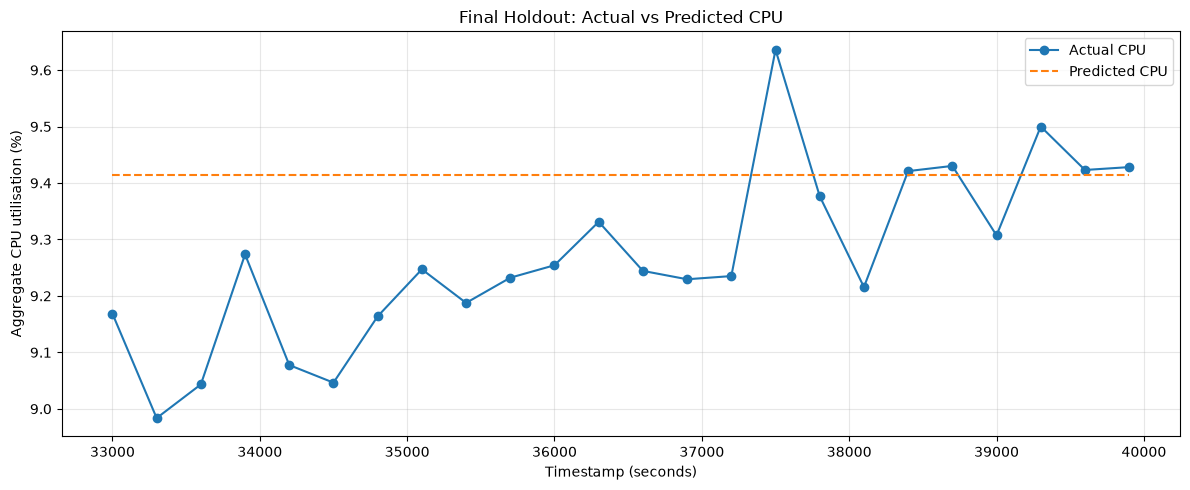

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    holdout["timestamp"],
    actual_cpu,
    marker="o",
    label="Actual CPU"
)

plt.plot(
    holdout["timestamp"],
    predicted_cpu,
    linestyle="--",
    label="Predicted CPU"
)

plt.xlabel("Timestamp (seconds)")
plt.ylabel("Aggregate CPU utilisation (%)")
plt.title("Final Holdout: Actual vs Predicted CPU")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 31. Compare actual and predicted holdout levels

Compare the mean, minimum and maximum actual holdout CPU utilisation with the predicted level.

This comparison helps explain any systematic bias. If the holdout mean differs from the training mean, a historical-mean forecast will remain fixed at the training level and will not adapt to that shift.


In [43]:
errors = actual_cpu - predicted_cpu

print(f"Mean error: {errors.mean():.6f}")
print(f"Maximum underprediction: {errors.max():.6f}")
print(f"Maximum overprediction: {errors.min():.6f}")
print(f"Underprediction points: {(errors > 0).sum()}")
print(f"Overprediction points: {(errors < 0).sum()}")

Mean error: -0.145101
Maximum underprediction: 0.221901
Maximum overprediction: -0.430476
Underprediction points: 6
Overprediction points: 18


## 32. Summary and interpretation

The selected approach uses a constant forecast for active VM count and the historical training mean for aggregate CPU utilisation.

The model selection is based on rolling-origin validation within the training period. The final holdout is Evaluatingd once after the model choices are fixed.

The results should be interpreted in context: a low average error does not mean that a constant forecast captures local peaks or sudden changes. For operational capacity planning, aggregate forecasts should be complemented by VM-level monitoring and suitable capacity safeguards.

The validation folds overlap and the available history is short. These limitations should be stated in the final report. Any additional machine-learning experiment, such as lag-feature Ridge Regression, should be added as a separate experiment and Evaluatingd with the same leakage-safe rolling-origin procedure before it is considered part of the final model comparison.


In [44]:
print("Actual holdout mean:", actual_cpu.mean())
print("Predicted holdout mean:", predicted_cpu.mean())

print("Actual holdout min:", actual_cpu.min())
print("Actual holdout max:", actual_cpu.max())

Actual holdout mean: 9.268987733051413
Predicted holdout mean: 9.414089019539007
Actual holdout min: 8.98361345296067
Actual holdout max: 9.63599020869164
